SECTION 1: IMPORTS AND VERSION CHECK
Python version   : 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
OpenCV version   : 4.14.0
NumPy version    : 2.1.3
Matplotlib ver.  : 3.10.0
scikit-image ver.: 0.25.2
Dataset path exists: True -> /kaggle/input/datasets/alielhenidy/tooth-dataset/Tooth dataset v4

SECTION 2: FOLDER STRUCTURE
[DIR] /kaggle/input/datasets/alielhenidy/tooth-dataset/Tooth dataset v4  (0 files)
[DIR] /kaggle/input/datasets/alielhenidy/tooth-dataset/Tooth dataset v4/train  (0 files)
[DIR] /kaggle/input/datasets/alielhenidy/tooth-dataset/Tooth dataset v4/train/images  (805 files)
    - 1000_F_200790927_4CaWF1akLlOE5L7lTHHKfo2QEcPfbOyW.jpg
    - 14280733311624550769.jpg
    - 22.jpeg
[DIR] /kaggle/input/datasets/alielhenidy/tooth-dataset/Tooth dataset v4/train/labels  (805 files)
    - 1000_F_200790927_4CaWF1akLlOE5L7lTHHKfo2QEcPfbOyW.txt
    - 14280733311624550769.txt
    - 22.txt
[DIR] /kaggle/input/datasets/alielhenidy/tooth-dataset/Tooth dataset v4/train/masks  (804

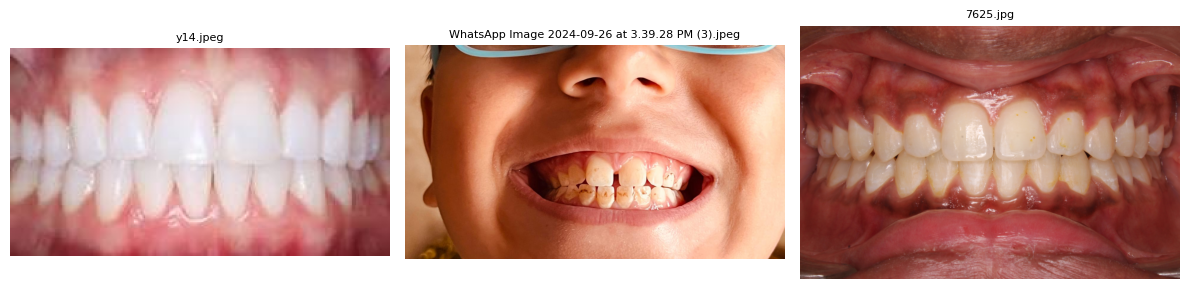


SECTION 4: DISPLAY SAMPLE MASKS


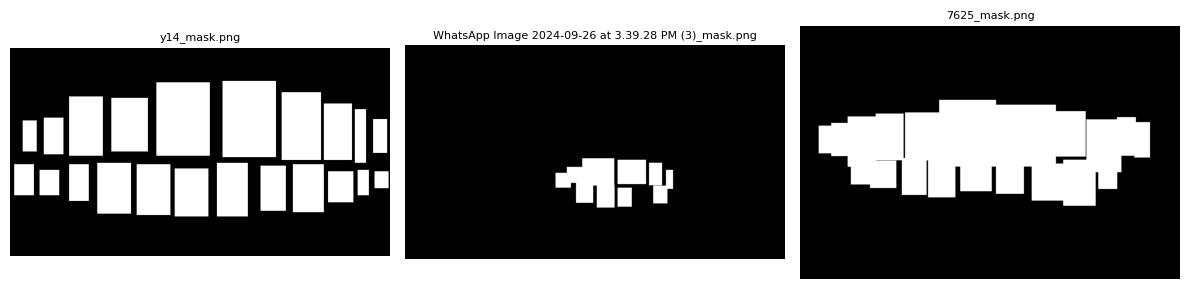


SECTION 5: OVERLAY CHECK


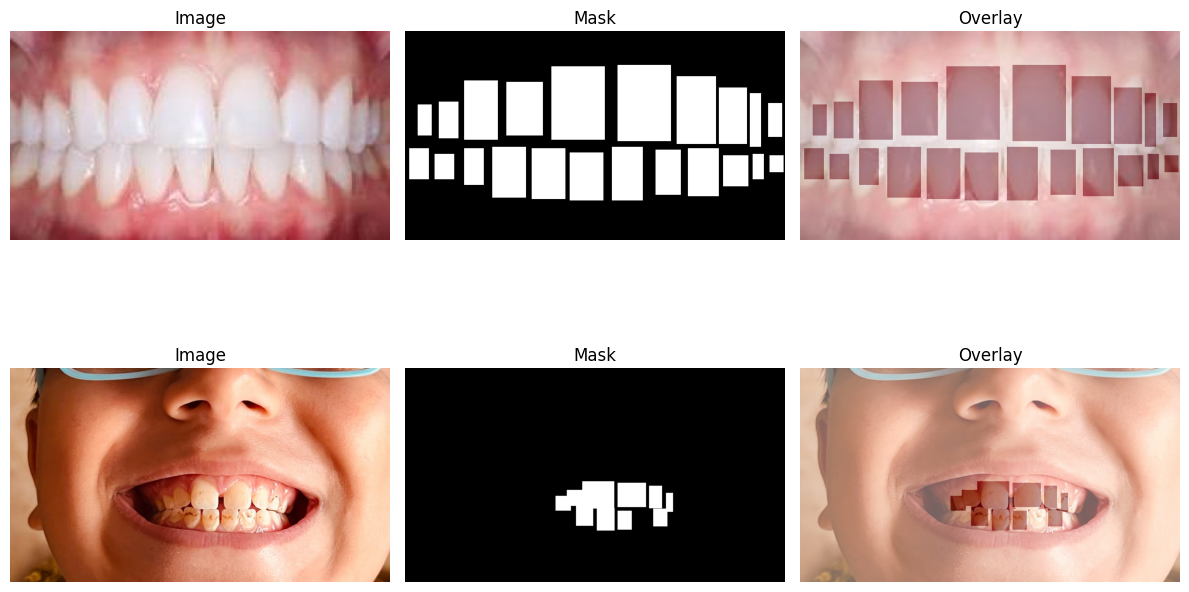


SECTION 6: LABEL FILE INSPECTION
Label file: /kaggle/input/datasets/alielhenidy/tooth-dataset/Tooth dataset v4/train/labels/1000_F_200790927_4CaWF1akLlOE5L7lTHHKfo2QEcPfbOyW.txt
Contents:
0 0.169000 0.233133 0.046000 0.184408
0 0.217000 0.229385 0.066000 0.137931
0 0.305000 0.198651 0.098000 0.196402
0 0.420500 0.221139 0.113000 0.217391
0 0.548500 0.206147 0.123000 0.220390
0 0.659500 0.206147 0.073000 0.190405
0 0.747500 0.200900 0.063000 0.224888
0 0.241500 0.537481 0.047000 0.130435
0 0.313500 0.560720 0.061000 0.167916
0 0.385500 0.576462 0.081000 0.187406
0 0.466500 0.564468 0.073000 0.202399
0 0.545000 0.602699 0.074000 0.182909
0 0.613500 0.602699 0.065000 0.128936
0 0.687500 0.570465 0.093000 0.199400
0 0.773500 0.547976 0.053000 0.115442

YOLO format explanation:
  Each line represents one bounding box, formatted as:
  class_id center_x center_y width height
  - class_id  : integer id of the object class (e.g. 0 = tooth)
  - center_x  : box center x-coordinate, normalized 0-

In [1]:
# explore_dataset.py
# Explores the NCT tooth dataset folder structure, verifies the environment,
# and displays sample images/masks/labels so we can sanity-check the data
# before building the rest of the pipeline.

import os
import sys
import random
import cv2
import numpy as np
import matplotlib.pyplot as plt
import skimage

# --------------------------------------------------------------------------
# CONSTANTS
# --------------------------------------------------------------------------
DATASET_ROOT = "/kaggle/input/datasets/alielhenidy/tooth-dataset/Tooth dataset v4"
OUTPUT_DIR = "/kaggle/working/module_0_environment"

TRAIN_IMAGES_DIR = os.path.join(DATASET_ROOT, "train", "images")
TRAIN_MASKS_DIR = os.path.join(DATASET_ROOT, "train", "masks")
TRAIN_LABELS_DIR = os.path.join(DATASET_ROOT, "train", "labels")
VAL_IMAGES_DIR = os.path.join(DATASET_ROOT, "val", "images")
VAL_MASKS_DIR = os.path.join(DATASET_ROOT, "val", "masks")
VAL_LABELS_DIR = os.path.join(DATASET_ROOT, "val", "labels")

IMAGE_EXTENSIONS = (".jpg", ".jpeg")  # dataset has both extensions mixed in
MASK_SUFFIX = "_mask.png"
LABEL_EXT = ".txt"

MAX_FILES_TO_LIST = 3       # how many filenames to preview per folder in the walk
NUM_DISPLAY_SAMPLES = 3     # how many images/masks to show side by side
NUM_OVERLAY_SAMPLES = 2     # how many image+mask+overlay rows to show
MASK_BINARY_THRESHOLD = 127 # pixel value above which a mask pixel counts as "tooth"
OVERLAY_ALPHA = 0.4         # transparency of the red mask overlay
DIM_SAMPLE_SIZE = 50        # how many images to sample when computing average dimensions
RANDOM_SEED = 42            # fixed seed so sample selection is reproducible


# --------------------------------------------------------------------------
# SECTION 1: IMPORTS AND VERSION CHECK
# --------------------------------------------------------------------------
def section1_version_check():
    print("=" * 70)
    print("SECTION 1: IMPORTS AND VERSION CHECK")
    print("=" * 70)
    print(f"Python version   : {sys.version}")
    print(f"OpenCV version   : {cv2.__version__}")
    print(f"NumPy version    : {np.__version__}")
    print(f"Matplotlib ver.  : {plt.matplotlib.__version__}")
    print(f"scikit-image ver.: {skimage.__version__}")
    print(f"Dataset path exists: {os.path.exists(DATASET_ROOT)} -> {DATASET_ROOT}")
    print()


# --------------------------------------------------------------------------
# SECTION 2: FOLDER STRUCTURE
# --------------------------------------------------------------------------
def count_files(directory, ext):
    if not os.path.isdir(directory):
        return 0
    return len([f for f in os.listdir(directory) if f.lower().endswith(ext)])


def section2_folder_structure():
    print("=" * 70)
    print("SECTION 2: FOLDER STRUCTURE")
    print("=" * 70)

    for root, dirs, files in os.walk(DATASET_ROOT):
        dirs.sort()
        files = sorted(files)
        print(f"[DIR] {root}  ({len(files)} files)")
        for f in files[:MAX_FILES_TO_LIST]:
            print(f"    - {f}")

    print("\nFile counts:")
    for split, images_dir, masks_dir, labels_dir in [
        ("train", TRAIN_IMAGES_DIR, TRAIN_MASKS_DIR, TRAIN_LABELS_DIR),
        ("val", VAL_IMAGES_DIR, VAL_MASKS_DIR, VAL_LABELS_DIR),
    ]:
        n_images = count_files(images_dir, IMAGE_EXTENSIONS)
        n_masks = count_files(masks_dir, ".png")
        n_labels = count_files(labels_dir, LABEL_EXT)
        print(f"  {split}: images={n_images}, masks={n_masks}, labels={n_labels}")
    print()


# --------------------------------------------------------------------------
# SHARED HELPER: MATCH IMAGES TO MASKS
# --------------------------------------------------------------------------
def get_mask_filename(image_filename):
    base_name, _ = os.path.splitext(image_filename)
    return base_name + MASK_SUFFIX


def find_matching_pairs(images_dir, masks_dir):
    pairs = []
    if not os.path.isdir(images_dir):
        return pairs
    for image_filename in sorted(os.listdir(images_dir)):
        if not image_filename.lower().endswith(IMAGE_EXTENSIONS):
            continue
        mask_path = os.path.join(masks_dir, get_mask_filename(image_filename))
        if os.path.exists(mask_path):
            image_path = os.path.join(images_dir, image_filename)
            pairs.append((image_path, mask_path))
    return pairs


def sample_pairs(pairs, k, seed=RANDOM_SEED):
    rng = random.Random(seed)
    return rng.sample(pairs, min(k, len(pairs)))


# --------------------------------------------------------------------------
# SECTION 3: DISPLAY SAMPLE IMAGES
# --------------------------------------------------------------------------
def section3_display_images(sample):
    print("=" * 70)
    print("SECTION 3: DISPLAY SAMPLE IMAGES")
    print("=" * 70)

    fig, axes = plt.subplots(1, len(sample), figsize=(4 * len(sample), 4))
    for ax, (image_path, _) in zip(axes, sample):
        image_bgr = cv2.imread(image_path)
        image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
        ax.imshow(image_rgb)
        ax.set_title(os.path.basename(image_path), fontsize=8)
        ax.axis("off")
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, "sample_images.png"))
    plt.show()
    print()


# --------------------------------------------------------------------------
# SECTION 4: DISPLAY SAMPLE MASKS
# --------------------------------------------------------------------------
def section4_display_masks(sample):
    print("=" * 70)
    print("SECTION 4: DISPLAY SAMPLE MASKS")
    print("=" * 70)

    fig, axes = plt.subplots(1, len(sample), figsize=(4 * len(sample), 4))
    for ax, (_, mask_path) in zip(axes, sample):
        mask_gray = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
        ax.imshow(mask_gray, cmap="gray")
        ax.set_title(os.path.basename(mask_path), fontsize=8)
        ax.axis("off")
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, "sample_masks.png"))
    plt.show()
    print()


# --------------------------------------------------------------------------
# SECTION 5: OVERLAY CHECK
# --------------------------------------------------------------------------
def section5_overlay_check(overlay_sample):
    print("=" * 70)
    print("SECTION 5: OVERLAY CHECK")
    print("=" * 70)

    fig, axes = plt.subplots(len(overlay_sample), 3, figsize=(12, 4 * len(overlay_sample)))
    if len(overlay_sample) == 1:
        axes = [axes]

    for row, (image_path, mask_path) in zip(axes, overlay_sample):
        image_bgr = cv2.imread(image_path)
        image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
        mask_gray = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
        mask_binary = (mask_gray > MASK_BINARY_THRESHOLD).astype(np.uint8)

        row[0].imshow(image_rgb)
        row[0].set_title("Image")
        row[0].axis("off")

        row[1].imshow(mask_binary, cmap="gray")
        row[1].set_title("Mask")
        row[1].axis("off")

        row[2].imshow(image_rgb)
        row[2].imshow(mask_binary, cmap="Reds", alpha=OVERLAY_ALPHA)
        row[2].set_title("Overlay")
        row[2].axis("off")

    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, "overlay_check.png"))
    plt.show()
    print()


# --------------------------------------------------------------------------
# SECTION 6: LABEL FILE INSPECTION
# --------------------------------------------------------------------------
def section6_label_inspection():
    print("=" * 70)
    print("SECTION 6: LABEL FILE INSPECTION")
    print("=" * 70)

    label_files = sorted(f for f in os.listdir(TRAIN_LABELS_DIR) if f.endswith(LABEL_EXT))
    if not label_files:
        print("No label files found.")
        print()
        return

    label_path = os.path.join(TRAIN_LABELS_DIR, label_files[0])
    with open(label_path, "r") as f:
        content = f.read()

    print(f"Label file: {label_path}")
    print("Contents:")
    print(content)

    print("YOLO format explanation:")
    print("  Each line represents one bounding box, formatted as:")
    print("  class_id center_x center_y width height")
    print("  - class_id  : integer id of the object class (e.g. 0 = tooth)")
    print("  - center_x  : box center x-coordinate, normalized 0-1 (fraction of image width)")
    print("  - center_y  : box center y-coordinate, normalized 0-1 (fraction of image height)")
    print("  - width     : box width, normalized 0-1 (fraction of image width)")
    print("  - height    : box height, normalized 0-1 (fraction of image height)")
    print()


# --------------------------------------------------------------------------
# SECTION 7: SUMMARY STATISTICS
# --------------------------------------------------------------------------
def section7_summary(train_pairs, val_pairs):
    print("=" * 70)
    print("SECTION 7: SUMMARY STATISTICS")
    print("=" * 70)

    print(f"Total image-mask pairs in train: {len(train_pairs)}")
    print(f"Total image-mask pairs in val  : {len(val_pairs)}")

    dim_sample = sample_pairs(train_pairs + val_pairs, DIM_SAMPLE_SIZE)
    heights, widths = [], []
    for image_path, _ in dim_sample:
        image = cv2.imread(image_path)
        h, w = image.shape[:2]
        heights.append(h)
        widths.append(w)

    avg_h = np.mean(heights) if heights else 0
    avg_w = np.mean(widths) if widths else 0
    print(f"Average image dimensions (sample of {len(dim_sample)}): "
          f"{avg_w:.1f} x {avg_h:.1f} (width x height)")

    all_good = len(train_pairs) > 0 and len(val_pairs) > 0
    print(f"Confirmation: dataset looks correct = {all_good}")
    print()


# --------------------------------------------------------------------------
# MAIN
# --------------------------------------------------------------------------
if __name__ == "__main__":
    os.makedirs(OUTPUT_DIR, exist_ok=True)

    section1_version_check()
    section2_folder_structure()

    train_pairs = find_matching_pairs(TRAIN_IMAGES_DIR, TRAIN_MASKS_DIR)
    val_pairs = find_matching_pairs(VAL_IMAGES_DIR, VAL_MASKS_DIR)

    display_sample = sample_pairs(train_pairs, NUM_DISPLAY_SAMPLES)
    overlay_sample = sample_pairs(train_pairs, NUM_OVERLAY_SAMPLES)

    section3_display_images(display_sample)
    section4_display_masks(display_sample)
    section5_overlay_check(overlay_sample)
    section6_label_inspection()
    section7_summary(train_pairs, val_pairs)

In [2]:
!pip install -q "git+https://github.com/SysCV/sam-hq.git" 
!pip install ultralytics
!pip install monai

  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 34.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.0/96.0 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 38.7 MB/s eta 0:00:00


[train] found 782 matched image/mask pairs


[train] preprocessing: 100%|██████████| 782/782 [00:17<00:00, 45.57it/s]


[val] found 209 matched image/mask pairs


[val] preprocessing: 100%|██████████| 209/209 [00:10<00:00, 20.25it/s]


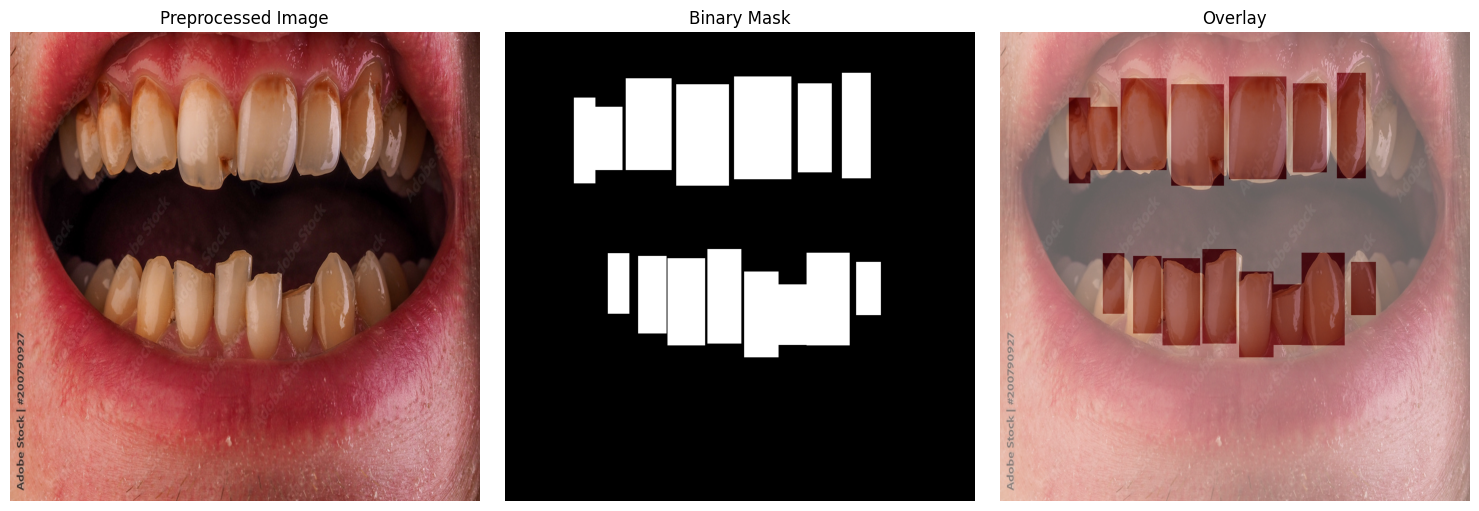

In [3]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

IMG_SIZE = 1024
IMAGE_EXTENSIONS = (".jpg", ".jpeg")  # dataset has both extensions mixed in
MASK_SUFFIX = "_mask.png"
MASK_BINARY_THRESHOLD = 127

DATASET_ROOT = "/kaggle/input/datasets/alielhenidy/tooth-dataset/Tooth dataset v4"
OUTPUT_ROOT = "/kaggle/working/processed"


def get_mask_filename(image_filename):
    base_name, _ = os.path.splitext(image_filename)
    return base_name + MASK_SUFFIX


def find_matching_pairs(images_dir, masks_dir):
    pairs = []
    for image_filename in sorted(os.listdir(images_dir)):
        if not image_filename.lower().endswith(IMAGE_EXTENSIONS):
            continue
        mask_path = os.path.join(masks_dir, get_mask_filename(image_filename))
        if os.path.exists(mask_path):
            pairs.append((os.path.join(images_dir, image_filename), mask_path))
    return pairs


def process_image(image_path):
    image_bgr = cv2.imread(image_path)
    image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
    # cv2.INTER_CUBIC is the same bicubic interpolation as skimage's order=3,
    # but OpenCV's native implementation is dramatically faster - no separate
    # Python-level anti-aliasing pass, which was the main preprocessing
    # bottleneck on large source photos.
    image_resized = cv2.resize(image_rgb, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_CUBIC)
    # Stored as uint8 (0-255), not normalized float32, to keep disk usage down
    # (~4x smaller); normalization happens on load in the training Dataset instead.
    return image_resized.astype(np.uint8)


def process_mask(mask_path):
    mask_gray = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    # INTER_NEAREST is cv2's nearest-neighbor mode - same reasoning as before:
    # masks are label maps, so we must not interpolate between class values.
    mask_resized = cv2.resize(mask_gray, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_NEAREST)
    return (mask_resized > MASK_BINARY_THRESHOLD).astype(np.uint8)


def process_split(split_name):
    images_dir = os.path.join(DATASET_ROOT, split_name, "images")
    masks_dir = os.path.join(DATASET_ROOT, split_name, "masks")
    out_images_dir = os.path.join(OUTPUT_ROOT, split_name, "images")
    out_masks_dir = os.path.join(OUTPUT_ROOT, split_name, "masks")
    os.makedirs(out_images_dir, exist_ok=True)
    os.makedirs(out_masks_dir, exist_ok=True)

    pairs = find_matching_pairs(images_dir, masks_dir)
    print(f"[{split_name}] found {len(pairs)} matched image/mask pairs")

    first_saved_paths = None
    for image_path, mask_path in tqdm(pairs, desc=f"[{split_name}] preprocessing"):
        image_array = process_image(image_path)
        mask_array = process_mask(mask_path)

        base_name = os.path.splitext(os.path.basename(image_path))[0]
        out_image_path = os.path.join(out_images_dir, base_name + ".npy")
        out_mask_path = os.path.join(out_masks_dir, base_name + ".npy")

        np.save(out_image_path, image_array)
        np.save(out_mask_path, mask_array)

        if first_saved_paths is None:
            first_saved_paths = (out_image_path, out_mask_path)

    return first_saved_paths


def visualize_sample(image_npy_path, mask_npy_path):
    image_array = np.load(image_npy_path)
    mask_array = np.load(mask_npy_path)

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    axes[0].imshow(image_array)
    axes[0].set_title("Preprocessed Image")
    axes[0].axis("off")

    axes[1].imshow(mask_array, cmap="gray")
    axes[1].set_title("Binary Mask")
    axes[1].axis("off")

    axes[2].imshow(image_array)
    axes[2].imshow(mask_array, cmap="Reds", alpha=0.4)
    axes[2].set_title("Overlay")
    axes[2].axis("off")

    plt.tight_layout()
    plt.show()


if __name__ == "__main__":
    train_sample = process_split("train")
    val_sample = process_split("val")

    sample_to_show = train_sample if train_sample is not None else val_sample
    if sample_to_show is not None:
        visualize_sample(*sample_to_show)
    else:
        print("No processed samples found - check that DATASET_ROOT is correct.")

In [4]:
import os, glob, shutil

target_dir = "/kaggle/working/processed"

# Check what's actually in SmileImages dataset input right now
print("=== Files found in /kaggle/input/ ===")
for root, dirs, files in os.walk("/kaggle/input"):
    npy_files = [f for f in files if f.endswith(".npy")]
    if npy_files:
        print(f"{root}: {len(npy_files)} .npy files")

print("\n=== Copying SmileImages .npy files ===")
copied = 0
for npy_file in glob.glob("/kaggle/input/**/*.npy", recursive=True):
    # Skip files already from notebook-a-meowmeow (NCT, already copied)
    if "notebook-a-meowmeow" in npy_file:
        continue
    
    fname = os.path.basename(npy_file)
    split = "val" if "/val/" in npy_file else "train"
    folder = "images" if "/images/" in npy_file else "masks"
    dest = f"{target_dir}/{split}/{folder}/{fname}"
    
    if not os.path.exists(dest):
        shutil.copy(npy_file, dest)
        copied += 1

train_count = len(os.listdir(f"{target_dir}/train/images"))
val_count   = len(os.listdir(f"{target_dir}/val/images"))
print(f"Newly copied: {copied} files")
print(f"✅ Total combined: {train_count} train | {val_count} val")
# Target: ~900 train | ~238 val

=== Files found in /kaggle/input/ ===
/kaggle/input/datasets/hemantdarur/smileimages/processed/val/images: 29 .npy files
/kaggle/input/datasets/hemantdarur/smileimages/processed/val/masks: 29 .npy files
/kaggle/input/datasets/hemantdarur/smileimages/processed/train/images: 118 .npy files
/kaggle/input/datasets/hemantdarur/smileimages/processed/train/masks: 118 .npy files
/kaggle/input/datasets/hemantdarur/notebook-a-meowmeow/processed/val/images: 209 .npy files
/kaggle/input/datasets/hemantdarur/notebook-a-meowmeow/processed/val/masks: 209 .npy files
/kaggle/input/datasets/hemantdarur/notebook-a-meowmeow/processed/train/images: 782 .npy files
/kaggle/input/datasets/hemantdarur/notebook-a-meowmeow/processed/train/masks: 782 .npy files

=== Copying SmileImages .npy files ===
Newly copied: 294 files
✅ Total combined: 900 train | 238 val


In [5]:
#!/usr/bin/env python3
"""
scripts/finetune_medsam_kaggle.py

Kaggle-Ready MedSAM Fine-Tuning Script
--------------------------------------
Answers: "Which checkpoint do I fine-tune from?"
 -> Answer: You fine-tune MedSAM using `medsam_tooth_best.pth` (from Notebook_A_meowmeow / DentalMedSAM)!
    YOLO is NOT for fine-tuning MedSAM — YOLO is purely a bounding box detector.

Features:
 1. Automatically searches for `medsam_tooth_best.pth` across Kaggle datasets & local dirs.
 2. Resumes training from your existing fine-tuned weights for maximum accuracy.
 3. Supports differential learning rate (unfreezes image encoder safely).
 4. Automatic Mixed Precision (AMP) + native SoftDice & BCE loss.
"""

import os
import sys
import glob
import random
import time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from segment_anything import sam_model_registry

# --------------------------------------------------------------------------
# PATH RESOLUTION & CHECKPOINT SEARCH
# --------------------------------------------------------------------------
def find_checkpoint():
    """
    Searches for the existing fine-tuned MedSAM checkpoint in Kaggle input datasets
    or local working directories.
    """
    candidates = [
        "/kaggle/input/notebook-a-meowmeow/checkpoints/medsam_tooth_best.pth",
        "/kaggle/input/datasets/hemantdarur/notebook-a-meowmeow/checkpoints/medsam_tooth_best.pth",
        "/kaggle/input/dentalmedsam/checkpoints/medsam_tooth_best.pth",
        "/kaggle/working/checkpoints/medsam_tooth_best.pth",
        "./checkpoints/medsam_tooth_best.pth",
        "../checkpoints/medsam_tooth_best.pth"
    ]
    # Also search any wildcard under /kaggle/input/
    wildcard_matches = glob.glob("/kaggle/input/**/medsam_tooth_best.pth", recursive=True)
    candidates.extend(wildcard_matches)

    for p in candidates:
        if os.path.exists(p):
            print(f"[Checkpoint Found] Using pre-trained tooth checkpoint: {p}")
            return p

    print("[Info] No existing medsam_tooth_best.pth found in input datasets.")
    print("      Will initialize from base SAM ViT-B weights.")
    return None

def find_data_dir():
    """Locates processed dataset directory (.npy images and masks)."""
    candidates = [
        "/kaggle/working/processed",
        "/kaggle/input/notebook-a-meowmeow/processed",
        "/kaggle/input/dentalmedsam/processed",
        "./data/processed",
        "../data/processed"
    ]
    for p in candidates:
        if os.path.exists(os.path.join(p, "train", "images")):
            print(f"[Dataset Found] Using processed data directory: {p}")
            return p
    return "./data/processed"

# --------------------------------------------------------------------------
# CONFIGURATION
# --------------------------------------------------------------------------
PRETRAINED_CHECKPOINT = find_checkpoint()
BASE_SAM_WEIGHTS = "work_dir/SAM/sam_vit_b_01ec64.pth"
OUTPUT_DIR = "/kaggle/working/checkpoints" if os.path.exists("/kaggle/working") else "./checkpoints"
BEST_CHECKPOINT_PATH = os.path.join(OUTPUT_DIR, "medsam_tooth_best.pth")
DATA_DIR = find_data_dir()

NUM_EPOCHS = 20
BATCH_SIZE = 1  # SAM predict_masks requires batch_size=1 during training
LEARNING_RATE = 1e-4
ENCODER_LEARNING_RATE = 1e-5
WEIGHT_DECAY = 0.01
BBOX_SHIFT = 20
VAL_EVERY_N_EPOCHS = 5
FREEZE_IMAGE_ENCODER = False  # Set to False to adapt Vision Transformer encoder
USE_AMP = True
RANDOM_SEED = 42

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# --------------------------------------------------------------------------
# LOSS FUNCTIONS
# --------------------------------------------------------------------------
class SoftDiceLoss(nn.Module):
    def __init__(self, smooth=1.0):
        super().__init__()
        self.smooth = smooth

    def forward(self, logits, targets):
        probs = torch.sigmoid(logits)
        probs_flat = probs.view(-1)
        targets_flat = targets.view(-1)
        intersection = (probs_flat * targets_flat).sum()
        dice = (2.0 * intersection + self.smooth) / (probs_flat.sum() + targets_flat.sum() + self.smooth)
        return 1.0 - dice

class CombinedLoss(nn.Module):
    def __init__(self):
        super().__init__()
        self.dice = SoftDiceLoss()
        self.bce = nn.BCEWithLogitsLoss()

    def forward(self, logits, targets):
        return self.dice(logits, targets) + self.bce(logits, targets)

# --------------------------------------------------------------------------
# DATASET & AUGMENTATIONS
# --------------------------------------------------------------------------
def get_bbox_from_mask(mask):
    y_indices, x_indices = np.where(mask > 0)
    if len(x_indices) == 0:
        return np.array([0, 0, 1024, 1024], dtype=np.float32)
    x_min, x_max = x_indices.min(), x_indices.max()
    y_min, y_max = y_indices.min(), y_indices.max()
    h, w = mask.shape

    x_min = max(0, x_min - random.randint(0, BBOX_SHIFT))
    x_max = min(w, x_max + random.randint(0, BBOX_SHIFT))
    y_min = max(0, y_min - random.randint(0, BBOX_SHIFT))
    y_max = min(h, y_max + random.randint(0, BBOX_SHIFT))
    return np.array([x_min, y_min, x_max, y_max], dtype=np.float32)

class ToothDataset(Dataset):
    def __init__(self, data_dir, split, augment=False):
        self.images_dir = os.path.join(data_dir, split, "images")
        self.masks_dir = os.path.join(data_dir, split, "masks")
        if os.path.exists(self.images_dir):
            self.filenames = sorted([f for f in os.listdir(self.images_dir) if f.endswith(".npy")])
        else:
            self.filenames = []
        self.augment = augment

    def __len__(self):
        return len(self.filenames)

    def __getitem__(self, idx):
        filename = self.filenames[idx]
        image = np.load(os.path.join(self.images_dir, filename))
        mask = np.load(os.path.join(self.masks_dir, filename))

        if self.augment:
            if random.random() < 0.5:
                image = np.ascontiguousarray(image[:, ::-1, :])
                mask = np.ascontiguousarray(mask[:, ::-1])

        image = image.astype(np.float32) / 255.0
        bbox = get_bbox_from_mask(mask)

        image_tensor = torch.from_numpy(image).permute(2, 0, 1).float()
        mask_tensor = torch.from_numpy(mask).unsqueeze(0).float()
        bbox_tensor = torch.from_numpy(bbox).float()

        return image_tensor, mask_tensor, bbox_tensor

# --------------------------------------------------------------------------
# MEDSAM FORWARD PASS
# --------------------------------------------------------------------------
def medsam_forward(model, image, bbox):
    if FREEZE_IMAGE_ENCODER:
        with torch.no_grad():
            image_embedding = model.image_encoder(image)
    else:
        image_embedding = model.image_encoder(image)

    box_torch = bbox if bbox.dim() == 3 else bbox.unsqueeze(1)

    with torch.no_grad():
        sparse_embeddings, dense_embeddings = model.prompt_encoder(
            points=None, boxes=box_torch, masks=None
        )

    low_res_masks, _ = model.mask_decoder(
        image_embeddings=image_embedding,
        image_pe=model.prompt_encoder.get_dense_pe(),
        sparse_prompt_embeddings=sparse_embeddings,
        dense_prompt_embeddings=dense_embeddings,
        multimask_output=False,
    )

    return F.interpolate(low_res_masks, size=image.shape[-2:], mode="bilinear", align_corners=False)

# --------------------------------------------------------------------------
# METRICS & TRAINING LOOP
# --------------------------------------------------------------------------
def compute_dice(pred_binary, target):
    intersection = (pred_binary * target).sum()
    return ((2.0 * intersection + 1e-6) / (pred_binary.sum() + target.sum() + 1e-6)).item()

def validate(model, dataloader):
    model.eval()
    scores = []
    with torch.no_grad():
        for images, masks, bboxes in dataloader:
            images, masks, bboxes = images.to(DEVICE), masks.to(DEVICE), bboxes.to(DEVICE)
            with torch.amp.autocast(DEVICE.type, enabled=USE_AMP):
                pred_logits = medsam_forward(model, images, bboxes)
            pred_binary = (torch.sigmoid(pred_logits) > 0.5).float()
            scores.append(compute_dice(pred_binary, masks))
    return float(np.mean(scores)) if scores else 0.0

def main():
    random.seed(RANDOM_SEED)
    torch.manual_seed(RANDOM_SEED)
    os.makedirs(OUTPUT_DIR, exist_ok=True)

    print(f"Running on Device: {DEVICE}")

    # 1. Load Model Architecture
    model = sam_model_registry["vit_b"](checkpoint=None)

    # Freeze prompt encoder
    for param in model.prompt_encoder.parameters():
        param.requires_grad = False

    # 2. Load Weights (Prioritize existing tooth checkpoint -> fallback to base SAM)
    weights_to_load = PRETRAINED_CHECKPOINT if PRETRAINED_CHECKPOINT else BASE_SAM_WEIGHTS
    if os.path.exists(weights_to_load):
        print(f"Loading checkpoint weights from: {weights_to_load}")
        state_dict = torch.load(weights_to_load, map_location=DEVICE)
        model.load_state_dict(state_dict, strict=False)
    else:
        print(f"Warning: Checkpoint {weights_to_load} not found on disk. Initializing base SAM model.")

    if FREEZE_IMAGE_ENCODER:
        for param in model.image_encoder.parameters():
            param.requires_grad = False

    model.to(DEVICE)

    # 3. Data Loaders
    train_dataset = ToothDataset(DATA_DIR, "train", augment=True)
    val_dataset = ToothDataset(DATA_DIR, "val", augment=False)

    if len(train_dataset) == 0:
        print(f"Error: No training files found in {DATA_DIR}/train/images.")
        print("Please check your DATA_DIR path or run dataset preprocessing first.")
        sys.exit(1)

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

    print(f"Dataset Loaded: {len(train_dataset)} train samples, {len(val_dataset)} val samples.")

    # 4. Optimizer
    if FREEZE_IMAGE_ENCODER:
        optimizer = torch.optim.AdamW(model.mask_decoder.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    else:
        optimizer = torch.optim.AdamW([
            {"params": model.mask_decoder.parameters(), "lr": LEARNING_RATE},
            {"params": model.image_encoder.parameters(), "lr": ENCODER_LEARNING_RATE}
        ], weight_decay=WEIGHT_DECAY)

    criterion = CombinedLoss()
    scaler = torch.amp.GradScaler(DEVICE.type, enabled=USE_AMP)

    best_dsc = validate(model, val_loader) if len(val_dataset) > 0 else 0.0
    print(f"Initial Validation DSC Baseline: {best_dsc:.4f}")

    # 5. Training Loop
    print("\n--- Starting MedSAM Fine-Tuning ---")
    for epoch in range(1, NUM_EPOCHS + 1):
        model.train()
        total_loss = 0.0

        for images, masks, bboxes in train_loader:
            images, masks, bboxes = images.to(DEVICE), masks.to(DEVICE), bboxes.to(DEVICE)
            optimizer.zero_grad()

            with torch.amp.autocast(DEVICE.type, enabled=USE_AMP):
                logits = medsam_forward(model, images, bboxes)
                loss = criterion(logits, masks)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            total_loss += loss.item()

        avg_loss = total_loss / len(train_loader)
        print(f"Epoch [{epoch}/{NUM_EPOCHS}] - Loss: {avg_loss:.4f}")

        if epoch % VAL_EVERY_N_EPOCHS == 0 or epoch == NUM_EPOCHS:
            val_dsc = validate(model, val_loader)
            print(f"  -> Validation DSC: {val_dsc:.4f}")
            if val_dsc > best_dsc:
                best_dsc = val_dsc
                torch.save(model.state_dict(), BEST_CHECKPOINT_PATH)
                print(f"  -> New Best Checkpoint Saved to {BEST_CHECKPOINT_PATH} (DSC: {val_dsc:.4f})")

    print(f"\nFine-Tuning Complete! Best Validation DSC: {best_dsc:.4f}")

if __name__ == "__main__":
    main()


[Checkpoint Found] Using pre-trained tooth checkpoint: /kaggle/input/datasets/hemantdarur/notebook-a-meowmeow/checkpoints/medsam_tooth_best.pth
[Dataset Found] Using processed data directory: /kaggle/working/processed
Running on Device: cuda
Loading checkpoint weights from: /kaggle/input/datasets/hemantdarur/notebook-a-meowmeow/checkpoints/medsam_tooth_best.pth
Dataset Loaded: 900 train samples, 238 val samples.
Initial Validation DSC Baseline: 0.8528

--- Starting MedSAM Fine-Tuning ---
Epoch [1/20] - Loss: 0.3411
Epoch [2/20] - Loss: 0.3094
Epoch [3/20] - Loss: 0.2904
Epoch [4/20] - Loss: 0.2786
Epoch [5/20] - Loss: 0.2644
  -> Validation DSC: 0.8716
  -> New Best Checkpoint Saved to /kaggle/working/checkpoints/medsam_tooth_best.pth (DSC: 0.8716)
Epoch [6/20] - Loss: 0.2618
Epoch [7/20] - Loss: 0.2476
Epoch [8/20] - Loss: 0.2405
Epoch [9/20] - Loss: 0.2312
Epoch [10/20] - Loss: 0.2286
  -> Validation DSC: 0.8834
  -> New Best Checkpoint Saved to /kaggle/working/checkpoints/medsam_too